# Auditoría de datos históricos — Seventh Avenue, W29–W30

**Pregunta:** ¿hay conteos suficientes para representar las entradas de ambas intersecciones?

**Resultado:** necesitamos otra fuente para conservar la ubicación. Solo W29 entre Sixth y Seventh tiene datos: 288 intervalos en tres días de abril de 2019. Los otros seis tramos identificados no tienen registros en esta consulta. No se cambia la ubicación del proyecto.

Consulta: noviembre de 2026; fecha exacta y revisión en el manifiesto local. Solo consultas de lectura; sin datos sintéticos, entrenamiento ni implementación de SimPy.

## 1. Fuentes y ejecución

- [Dataset oficial y esquema](https://data.cityofnewyork.us/Transportation/Automated-Traffic-Volume-Counts/7ym2-wayt): conteos ATR de 15 minutos, muestreos que no cubren todo el año.
- [SODA 3.0](https://dev.socrata.com/docs/queries/): POST JSON con `query`, `pageNumber` desde 1 y `pageSize`; `includeSynthetic: false` omite columnas implícitas, no genera datos sintéticos.
- [App Token](https://dev.socrata.com/docs/app-tokens.html): solo encabezado `X-App-Token`; el Secret Token no se usa.
- [LION de DCP](https://services5.arcgis.com/GfwWNkhOj9bNBqoJ/ArcGIS/rest/services/LION/FeatureServer/0): geometrías, nodos y sentido de la red.

El helper en `src/auditoria_historicos.py` conserva respuestas y consultas sin credenciales en `resultados/auditoria_historicos/` (local, ignorado por Git). Con caché completa no hace peticiones. Para una nueva auditoría usar `ACTUALIZAR = True`; las tablas se recalculan con la nueva respuesta. Los textos interpretativos corresponden a la auditoría entregada.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / 'src'))
from auditoria_historicos import obtener_evidencia, OBJETIVO, CENTRO, RADIO_M, punto, leer_hojas_xlsx

ACTUALIZAR = False
SALIDA = obtener_evidencia(RAIZ, actualizar=ACTUALIZAR)
def leer(nombre):
    return json.loads((SALIDA / f'{nombre}.json').read_text())

manifest = leer('manifest')
display(pd.Series(manifest, name='Auditoría'))
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

fecha_consulta                      2026-11-07T23:48:11.458659-06:00
endpoint           https://data.cityofnewyork.us/api/v3/views/7ym...
rowsUpdatedAt                                             1773980461
radio_m                                                          915
centro_2263                                         [986277, 211852]
paginas_conteos                                                   13
nota               Inventarios agregados; 12739 filas descargadas...
Name: Auditoría, dtype: object

## 2. Esquema real y alcance de la consulta

`yr` contiene años de cuatro dígitos aunque la descripción diga dos. `wktgeom` es texto WKT de **puntos**, no trayectorias. `segmentid` refiere a LION 14; el servicio geográfico actual es otra versión: se contrastan también nodos y ubicación, no solo el ID.

Primero se agregan variantes amplias (`7`, `SEVENTH`, `29`, `30`), que abarcan `7 AV`, `7TH AVE`, `7 AVENUE`, `SEVENTH AVENUE`, `W 29 ST`, `WEST 30 STREET`, etc. Después se inspecciona **todo el inventario agregado de Manhattan**, para no depender de nombres, y se seleccionan puntos a ≤915 m del centro del tramo. Finalmente se consultan los IDs objetivo en todo el dataset, sin filtro de borough, junto con los candidatos cercanos. No se descarga el dataset completo.

In [2]:
esquema = leer('esquema')
columnas = pd.DataFrame([{'columna': x['fieldName'], 'tipo': x['dataTypeName'],
                         'significado': x.get('description', '')}
                        for x in esquema['columns'] if not x['fieldName'].startswith(':')])
display(columnas)
globales = pd.DataFrame(leer('global'))
globales['n'] = pd.to_numeric(globales['n'])
TOTAL_GLOBAL = int(globales.n.sum())
display(globales)
consultas = pd.DataFrame(leer('consultas'))
display(consultas[['nombre', 'query', 'page', 'filas']].drop_duplicates('nombre'))
print('Inventario por variantes:', len(leer('inventario_nombres')), 'combinaciones')
print('Inventario agregado de Manhattan:', len(leer('inventario_manhattan')), 'combinaciones')

,columna,tipo,significado
0,requestid,number,An unique ID that is generated for each counts...
1,boro,text,Lists which of the five administrative divisio...
2,yr,number,The two digit year portion of the date when th...
3,m,number,The two digit month portion of the date when t...
4,d,number,The two digit day portion of the date when the...
5,hh,number,The two digit hour portion of the time when th...
6,mm,number,The two digit start minute portion of the time...
7,vol,number,The total sum of count collected within a 15 m...
8,segmentid,number,The ID that identifies each segment of a stree...
9,wktgeom,text,A text markup language for representing vector...


,boro,n,primer_ano,ultimo_ano
0,Bronx,308124,2007,2026
1,Brooklyn,540695,2007,2026
2,Manhattan,343555,2000,2026
3,Queens,560928,2007,2026
4,Staten Island,121852,2000,2025


,nombre,query,page,filas
0,global,"SELECT boro, count(*) AS n, min(yr) AS primer_...","{'pageNumber': 1, 'pageSize': 10000}",5
1,inventario_nombres,"SELECT segmentid, street, fromst, tost, direct...","{'pageNumber': 1, 'pageSize': 10000}",95
2,inventario_manhattan,"SELECT segmentid, street, fromst, tost, direct...","{'pageNumber': 1, 'pageSize': 10000}",809
3,resumen_ids,"SELECT segmentid, boro, street, fromst, tost, ...","{'pageNumber': 1, 'pageSize': 10000}",30
4,conteos,"SELECT * WHERE segmentid IN (32830,33001,33006...","{'pageNumber': 1, 'pageSize': 1000}",1000


Inventario por variantes: 95 combinaciones
Inventario agregado de Manhattan: 809 combinaciones


## 3. Localización por LION, nodos y geometrías

Los nodos **21334** (7 Av/W29) y **21335** (7 Av/W30) delimitan el segmento **33802**. El servicio LION declara EPSG:2263 (pies US). El CRS del WKT ATR no se declara en su diccionario: su interpretación en ese CRS se valida por correspondencia de IDs y proximidad a las líneas LION; las distancias son aproximadas. Los puntos ATR representan ubicaciones del conteo, no extremos del tramo.

Según `TrafDir` de la red actual: Seventh circula hacia el sur, W29 hacia el oeste y W30 hacia el este. Esto ubica los accesos; no demuestra que la señalización o la infraestructura fueran idénticas en 2019. Los nombres `6 Avenue Line` / `Broadway/7 Avenue Line` en límites ATR no convierten los conteos en datos ferroviarios: se contrasta el segmento de calle en LION.

CRS del servicio LION: {'wkid': 102718, 'latestWkid': 2263}
Propietario del servicio: DCP_GIS


,segmentid,ubicacion_y_funcion,registros,nodo_desde,nodo_hasta,TrafDir
0,33804,"7 Av, W30–W31: entrada desde el norte, sentido SB",0,0021335,0021337,A
1,33803,"W30, 8–7 Av: entrada desde el oeste, sentido EB",0,0021335,0021256,A
2,33802,"7 Av, W29–W30: tramo central / entrada desde e...",0,0021334,0021335,A
3,33894,"W29, Sixth–Seventh: entrada desde el este, sen...",288,0021380,0021334,W
4,33800,"7 Av, W28–W29: salida sur de W29",0,0021333,0021334,A
5,33801,"W29, 7–8 Av: salida oeste de W29",0,0021334,0021255,W
6,33896,"W30, 7–6 Av: salida este de W30",0,0021381,0021335,A


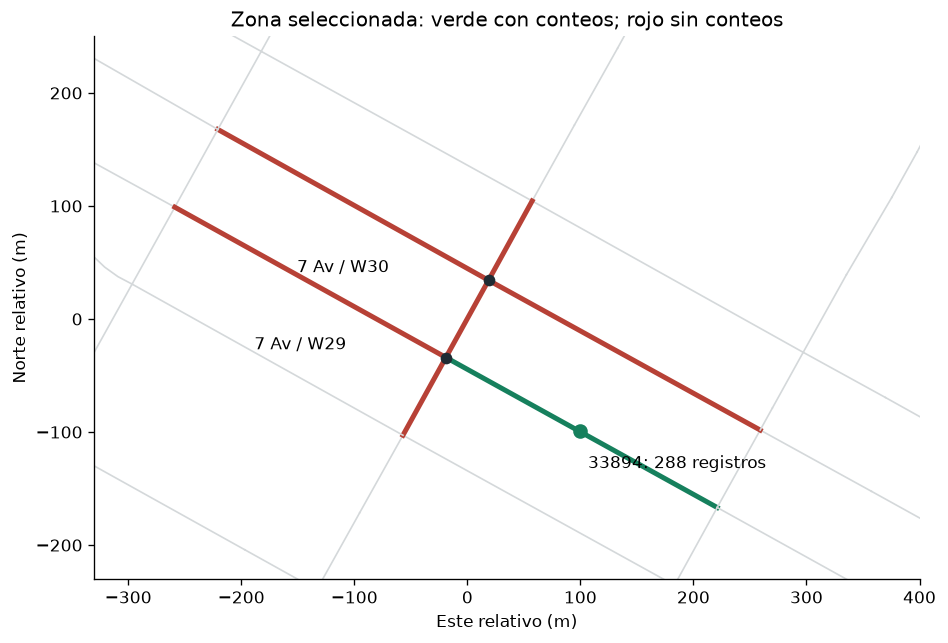

In [3]:
features = leer('lion_zona')['features']
lion = pd.DataFrame([f['attributes'] for f in features])
lion['segmentid'] = lion.SegmentID.astype(int)
lion = lion.drop_duplicates('segmentid').set_index('segmentid')
assert set(OBJETIVO).issubset(lion.index)
assert {lion.loc[33802, 'NodeIDFrom'], lion.loc[33802, 'NodeIDTo']} == {'0021334', '0021335'}
print('CRS del servicio LION:', leer('lion_esquema')['extent']['spatialReference'])
print('Propietario del servicio:', leer('lion_item')['owner'])
resumen_api = pd.DataFrame(leer('resumen_ids'))
resumen_api['segmentid'] = resumen_api.segmentid.astype(int)
resumen_api['n'] = resumen_api.n.astype(int)
n_por_id = resumen_api.groupby('segmentid').n.sum()
objetivo = pd.DataFrame([{'segmentid': sid, 'ubicacion_y_funcion': text,
                         'registros': int(n_por_id.get(sid, 0)),
                         'nodo_desde': lion.loc[sid, 'NodeIDFrom'],
                         'nodo_hasta': lion.loc[sid, 'NodeIDTo'],
                         'TrafDir': lion.loc[sid, 'TrafDir']}
                        for sid, text in OBJETIVO.items()])
display(objetivo)
objetivo.to_csv(SALIDA / 'segmentos_objetivo.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 7))
seen = set()
for f in features:
    sid = int(f['attributes']['SegmentID'])
    if sid in seen:
        continue
    seen.add(sid)
    for path in f['geometry']['paths']:
        xy = np.asarray(path)
        color = '#16805d' if sid == 33894 else '#b74136' if sid in OBJETIVO else '#d4d8da'
        ax.plot((xy[:, 0]-CENTRO[0])*0.3048, (xy[:, 1]-CENTRO[1])*0.3048,
                color=color, lw=3 if sid in OBJETIVO else 1)
for node, xy, label in [(21334, (986215,211740), '7 Av / W29'), (21335, (986339,211964), '7 Av / W30')]:
    ax.scatter((xy[0]-CENTRO[0])*0.3048, (xy[1]-CENTRO[1])*0.3048, color='#202b33', zorder=5)
    ax.annotate(label, ((xy[0]-CENTRO[0])*0.3048, (xy[1]-CENTRO[1])*0.3048), xytext=(-115, 5), textcoords='offset points')
x,y=punto(leer('cercanos')[next(i for i,r in enumerate(leer('cercanos')) if int(r['segmentid'])==33894)]['wktgeom'])
ax.scatter((x-CENTRO[0])*0.3048,(y-CENTRO[1])*0.3048,color='#16805d',s=60,zorder=6)
ax.annotate('33894: 288 registros',((x-CENTRO[0])*0.3048,(y-CENTRO[1])*0.3048),xytext=(5,-22),textcoords='offset points')
ax.set(xlim=(-330,400),ylim=(-230,250),xlabel='Este relativo (m)',ylabel='Norte relativo (m)',
       title='Zona seleccionada: verde con conteos; rojo sin conteos')
ax.set_aspect('equal');fig.tight_layout();fig.savefig(SALIDA/'mapa_cobertura.png');plt.show()

## 4. Auditoría de los registros descargados

Se conserva la fuente intacta; se convierten números y fechas para validar. Duplicado exacto: todas las columnas originales iguales. Duplicado de clave: mismo `requestid`, segmento, dirección y fecha/hora. Conflicto: esa clave tiene volúmenes diferentes. También se comprueban solapamientos entre solicitudes. Un volumen cero se cuenta como observación cero, sin concluir si hubo fallo del sensor.

In [4]:
raw = pd.DataFrame(leer('conteos'))
datos = raw.copy()
campos_numericos = ['requestid','segmentid','yr','m','d','hh','mm','vol']
for col in campos_numericos:
    datos[col] = pd.to_numeric(datos[col], errors='coerce')
datos['fecha'] = pd.to_datetime(dict(year=datos.yr, month=datos.m, day=datos.d), errors='coerce')
datos['fecha_hora'] = datos.fecha + pd.to_timedelta(datos.hh, unit='h') + pd.to_timedelta(datos.mm, unit='min')
# Tiempo de reloj local, sin zona horaria en la fuente; no resuelve horas repetidas por DST.
clave = ['requestid','segmentid','direction','fecha_hora']
clave_fisica = ['segmentid','direction','fecha_hora']
mal_tiempo = (datos.fecha.isna() | ~datos.hh.between(0,23) | ~datos.mm.isin([0,15,30,45])
              | (datos.hh % 1 != 0) | (datos.mm % 1 != 0))
mal_volumen = datos.vol.isna() | (datos.vol < 0) | (datos.vol % 1 != 0)
mal_direccion = ~datos.direction.isin(['NB','SB','EB','WB','NS','EW'])

# Control de completitud de la paginación contra agregados del servidor.
observados = datos.groupby('segmentid').size().sort_index()
esperados = n_por_id.sort_index()
assert observados.to_dict() == esperados.to_dict(), 'Descarga incompleta o fuente cambió durante la consulta.'
assert len(datos) == int(resumen_api.n.sum())
calidad=[]
for sid,g in datos.groupby('segmentid'):
    indices=g.index
    calidad.append({'segmentid':sid,'filas':len(g),'celdas_nulas':int(raw.loc[indices].isna().sum().sum()),
                    'conversiones_invalidas':int(g[campos_numericos].isna().sum().sum()),
                    'duplicados_exactos':int(raw.loc[indices].duplicated().sum()),
                    'duplicados_clave':int(g.duplicated(clave).sum()),
                    'conflictos_volumen':int((g.groupby(clave).vol.nunique()>1).sum()),
                    'solapamientos':int(g.duplicated(clave_fisica).sum()),
                    'tiempos_invalidos':int(mal_tiempo.loc[indices].sum()),
                    'volumenes_invalidos':int(mal_volumen.loc[indices].sum()),
                    'direcciones_invalidas':int(mal_direccion.loc[indices].sum()),
                    'ceros':int((g.vol==0).sum())})
calidad=pd.DataFrame(calidad)
display(calidad)
calidad.to_csv(SALIDA/'calidad_por_segmento.csv',index=False)
print(f'Descarga: {len(datos):,} filas, {datos.segmentid.nunique()} segmentos con datos, '
      f'{len(datos)/TOTAL_GLOBAL:.2%} de {TOTAL_GLOBAL:,} registros globales.')
display(calidad.drop(columns='segmentid').sum().to_frame('Total auditado'))

,segmentid,filas,celdas_nulas,conversiones_invalidas,duplicados_exactos,duplicados_clave,conflictos_volumen,solapamientos,tiempos_invalidos,volumenes_invalidos,direcciones_invalidas,ceros
0,32830,110,0,0,0,0,0,0,0,0,0,0
1,33001,783,0,0,0,0,0,0,0,0,0,3
2,33006,1,0,0,0,0,0,0,0,0,0,0
3,33010,282,0,0,0,0,0,0,0,0,0,0
4,33638,112,0,0,0,0,0,0,0,0,0,0
5,33639,790,0,0,0,0,0,0,0,0,0,0
6,33656,672,0,0,0,0,0,0,0,0,0,0
7,33662,864,0,0,0,0,0,0,0,0,0,0
8,33795,288,0,0,0,0,0,0,0,0,0,0
9,33814,72,0,0,0,0,0,0,0,0,0,0


Descarga: 12,739 filas, 25 segmentos con datos, 0.68% de 1,875,154 registros globales.


,Total auditado
filas,12739
celdas_nulas,0
conversiones_invalidas,0
duplicados_exactos,0
duplicados_clave,0
conflictos_volumen,0
solapamientos,0
tiempos_invalidos,0
volumenes_invalidos,0
direcciones_invalidas,0


## 5. Años, meses, días y campañas

`requestid` identifica una **solicitud de conteo**: se usa como proxy de campaña por segmento y dirección, no como prueba de una campaña independiente ni de continuidad. Una misma solicitud puede abarcar varios segmentos. Se muestran meses observados; los años intermedios sin filas no se rellenan con ceros de tráfico.

La cobertura diaria nominal es `intervalos únicos / 96`. La cobertura interna compara los intervalos dentro del primer y último registro de cada solicitud. Ninguna significa cobertura de todo el historial. Cerca de cambios de horario de verano, 96 es solo una convención de reloj local.

In [5]:
validos = datos.loc[~(mal_tiempo | mal_volumen | mal_direccion)].copy()
validos['dia'] = validos.fecha_hora.dt.strftime('%Y-%m-%d')
validos['mes'] = validos.fecha_hora.dt.strftime('%Y-%m')
validos['slot'] = validos.hh*4 + validos.mm//15
meses = validos.groupby(['segmentid','mes','direction']).agg(registros=('vol','size'),dias=('dia','nunique'),solicitudes=('requestid','nunique')).reset_index()
diaria = validos.groupby(['segmentid','requestid','direction','dia']).agg(
    registros=('vol','size'),intervalos=('slot','nunique'),volumen=('vol','sum'),inicio=('fecha_hora','min'),fin=('fecha_hora','max')).reset_index()
diaria['cobertura_nominal_pct'] = diaria.intervalos/96*100
campanas = validos.groupby(['segmentid','requestid','direction']).agg(
    registros=('vol','size'),intervalos=('fecha_hora','nunique'),dias=('dia','nunique'),inicio=('fecha_hora','min'),fin=('fecha_hora','max')).reset_index()
campanas['esperados_entre_extremos'] = ((campanas.fin-campanas.inicio)/pd.Timedelta(minutes=15)+1).astype(int)
campanas['faltantes_internos'] = campanas.esperados_entre_extremos-campanas.intervalos
campanas['cobertura_interna_pct'] = 100*campanas.intervalos/campanas.esperados_entre_extremos
filas=[]
for sid,g in validos.groupby('segmentid'):
    day=diaria[diaria.segmentid==sid]
    filas.append({'segmentid':sid,'calle':g.street.iloc[0],'registros':len(g),
                  'meses':', '.join(sorted(g.mes.unique())),'dias':g.dia.nunique(),
                  'solicitudes':g.requestid.nunique(),'direcciones':', '.join(sorted(g.direction.unique())),
                  'dias_direccion_completos':int((day.intervalos==96).sum()),
                  'min_15min':g.vol.min(),'max_15min':g.vol.max(),'media_15min':round(g.vol.mean(),2)})
cobertura=pd.DataFrame(filas)
display(cobertura)
display(campanas[campanas.segmentid==33894])
for name,table in [('cobertura_por_segmento',cobertura),('cobertura_mensual',meses),('cobertura_diaria',diaria),('campanas',campanas)]:
    table.to_csv(SALIDA/f'{name}.csv',index=False)
print('Totales: fechas con mediciones por segmento; no sumar días de diferentes segmentos como días independientes.')

,segmentid,calle,registros,meses,dias,solicitudes,direcciones,dias_direccion_completos,min_15min,max_15min,media_15min
0,32830,23RD ST APPROACH TO 7TH AVE,110,2011-09,2,1,WB,0,17,166,90.45
1,33001,5TH AVE BET 22ND & 23RD STS,783,2011-03,9,1,SB,7,0,398,233.57
2,33006,S/B 5TH AVE @ E 23RD ST,1,2009-01,1,1,SB,0,44,44,44.00
3,33010,S/B BROADWAY @ E 23RD ST,282,"2009-01, 2009-02",5,1,SB,2,15,228,118.04
4,33638,23RD ST W/O 7TH AVE,112,2011-09,2,1,EB,0,23,158,95.40
5,33639,7TH AVE APPROACH TO W 23RD ST,790,2011-09,10,1,SB,8,32,522,335.62
6,33656,8 AVENUE,672,2017-07,7,1,NB,7,78,586,354.41
7,33662,9 AVENUE,864,2023-10,3,1,"EB, SB, WB",9,7,341,124.47
8,33795,WEST 26 STREET,288,2019-04,3,1,EB,3,10,148,72.83
9,33814,WEST 34 STREET,72,2016-03,1,1,EB,0,11,369,260.65


,segmentid,requestid,direction,registros,intervalos,dias,inicio,fin,esperados_entre_extremos,faltantes_internos,cobertura_interna_pct
13,33894,30130,WB,288,288,3,2019-04-22,2019-04-24 23:45:00,288,0,100.0


Totales: fechas con mediciones por segmento; no sumar días de diferentes segmentos como días independientes.


## 6. Intervalos y volúmenes del único acceso observado

En **33894** se observan 288 intervalos, **96 por día**, del 22 al 24 de abril de 2019 (lunes a miércoles), dirección WB, solicitud 30130. No hay otras campañas en ese segmento. Los valores describen el flujo que pasó por el contador; bajo congestión pueden estar limitados por la descarga, y no medir la demanda que deseaba entrar.

,segmentid,requestid,direction,dia,registros,intervalos,volumen,inicio,fin,cobertura_nominal_pct
56,33894,30130,WB,2019-04-22,96,96,5759,2019-04-22,2019-04-22 23:45:00,100.0
57,33894,30130,WB,2019-04-23,96,96,6457,2019-04-23,2019-04-23 23:45:00,100.0
58,33894,30130,WB,2019-04-24,96,96,6827,2019-04-24,2019-04-24 23:45:00,100.0


,vehiculos_por_15_min
count,288.000000
mean,66.121528
std,27.489545
min,10.000000
25%,48.000000
50%,70.000000
75%,88.000000
max,112.000000


Volumen total observado: 19043 vehículos


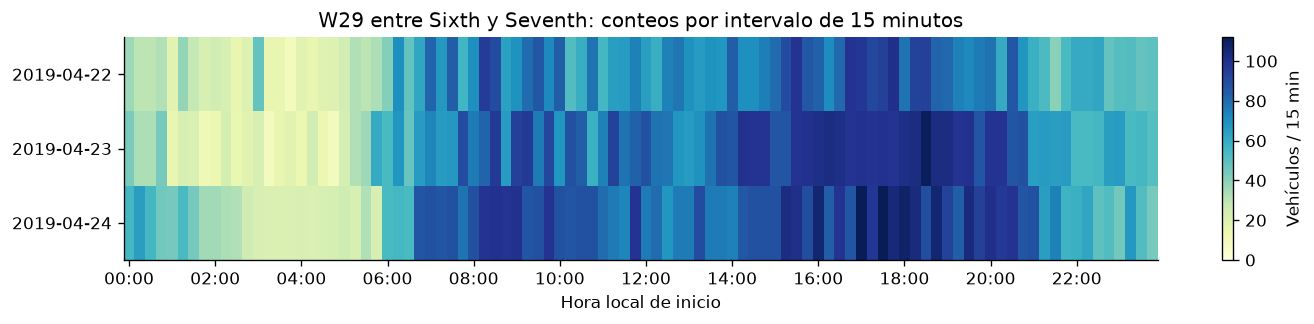

,media_vph,min_vph,max_vph,dias
hora,,,,
0,167.00,128,220,3
1,118.00,71,177,3
2,92.33,70,125,3
3,80.33,66,90,3
4,74.33,62,88,3
5,123.67,101,151,3
6,235.33,221,250,3
7,308.67,289,341,3
8,340.67,319,383,3


Horas completas: 72 rango: 62 – 425 veh/h


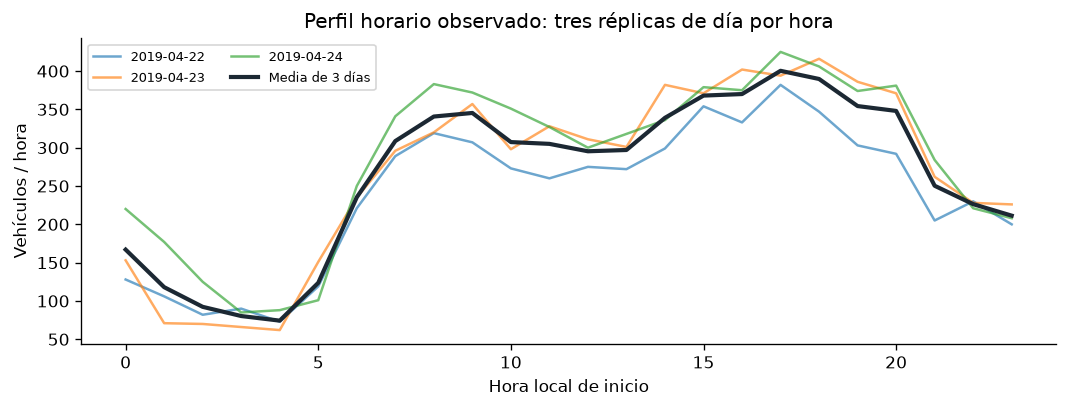

In [6]:
foco = validos[validos.segmentid==33894].copy()
assert len(foco)==288, 'La fuente cambió: actualizar interpretación del informe.'
display(diaria[diaria.segmentid==33894])
display(foco.vol.describe().to_frame('vehiculos_por_15_min'))
print('Volumen total observado:', int(foco.vol.sum()), 'vehículos')

matriz=foco.pivot(index='dia',columns='slot',values='vol').reindex(columns=range(96))
fig,ax=plt.subplots(figsize=(12,2.8))
im=ax.imshow(matriz.to_numpy(dtype=float),aspect='auto',cmap='YlGnBu',vmin=0)
ax.set_yticks(range(len(matriz)),matriz.index)
ax.set_xticks(range(0,96,8),[f'{h:02d}:00' for h in range(0,24,2)])
ax.set(title='W29 entre Sixth y Seventh: conteos por intervalo de 15 minutos',xlabel='Hora local de inicio')
fig.colorbar(im,ax=ax,label='Vehículos / 15 min');fig.tight_layout()
fig.savefig(SALIDA/'volumenes_15min.png');plt.show()

foco['hora_inicio']=foco.fecha_hora.dt.floor('h')
horaria=foco.groupby('hora_inicio').agg(intervalos=('mm','nunique'),vehiculos=('vol','sum')).reset_index()
horaria=horaria[horaria.intervalos==4].copy()
horaria['hora']=horaria.hora_inicio.dt.hour
horaria['dia']=horaria.hora_inicio.dt.strftime('%Y-%m-%d')
perfil=horaria.groupby('hora').agg(media_vph=('vehiculos','mean'),min_vph=('vehiculos','min'),max_vph=('vehiculos','max'),dias=('vehiculos','size'))
display(perfil.round(2))
print('Horas completas:',len(horaria),'rango:',int(horaria.vehiculos.min()),'–',int(horaria.vehiculos.max()),'veh/h')
fig,ax=plt.subplots(figsize=(9,3.5))
for dia,g in horaria.groupby('dia'):
    ax.plot(g.hora,g.vehiculos,label=dia,alpha=.65)
ax.plot(perfil.index,perfil.media_vph,color='#1c2833',lw=2.5,label='Media de 3 días')
ax.set(xlabel='Hora local de inicio',ylabel='Vehículos / hora',title='Perfil horario observado: tres réplicas de día por hora')
ax.legend(ncol=2,fontsize=8);fig.tight_layout();fig.savefig(SALIDA/'perfil_horario.png');plt.show()
horaria.to_csv(SALIDA/'volumenes_horarios_33894.csv',index=False)
perfil.to_csv(SALIDA/'perfil_horario_33894.csv')

## 7. Integridad espacial y advertencias del proveedor

Se revisan el diccionario y `ATR Location_Errors2025.xlsx`, adjuntos al esquema. Ninguno de los IDs descargados está en la lista publicada de errores; esto no certifica ausencia de otros errores.

Hay una inconsistencia adicional: **33662**, etiquetado `9 AVENUE`, tiene **288 filas EB y 288 WB**, además de 288 SB; la línea LION es un tramo norte–sur. Las 576 filas transversales requieren verificación de ubicación/sentido y no se recomiendan para calibración sin aclaración. La comparación con la red actual es una advertencia de compatibilidad, no una corrección automática de la fuente histórica.

In [7]:
errores=leer_hojas_xlsx(SALIDA/'ATR Location_Errors2025.xlsx')['sheet1']
ids_error={int(row[1]) for row in errores[2:] if len(row)>1 and str(row[1]).isdigit()}
coincidencias=sorted(set(datos.segmentid.astype(int)) & ids_error)
print('IDs auditados mencionados en el adjunto de errores:',coincidencias)
display(datos[datos.segmentid==33662].groupby(['street','direction']).size().rename('registros').reset_index())
lion_cerca=pd.DataFrame([f['attributes'] for f in leer('lion_cercanos')['features']]).drop_duplicates('SegmentID')
display(lion_cerca[lion_cerca.SegmentID=='0033662'])

# Distancia del punto ATR a la polilínea con el mismo ID: evidencia del enlace espacial.
def distancia_linea(p,paths):
    best=float('inf');p=np.asarray(p,dtype=float)
    for path in paths:
        for a,b in zip(path,path[1:]):
            a,b=np.asarray(a),np.asarray(b);v=b-a
            t=np.clip(np.dot(p-a,v)/np.dot(v,v),0,1) if np.dot(v,v)>0 else 0
            best=min(best,float(np.linalg.norm(p-(a+t*v))))
    return best*0.3048006096
lineas={int(f['attributes']['SegmentID']): f['geometry']['paths'] for f in leer('lion_cercanos')['features']}
geo=[]
for row in leer('cercanos'):
    sid=int(row['segmentid'])
    if sid in lineas:
        geo.append({'segmentid':sid,'distancia_punto_linea_m':round(distancia_linea(punto(row['wktgeom']),lineas[sid]),2)})
geo=pd.DataFrame(geo).drop_duplicates()
display(geo[geo.segmentid.isin([33894,33656,33821,33913])])
geo.to_csv(SALIDA/'validacion_geometrica.csv',index=False)

IDs auditados mencionados en el adjunto de errores: []


,street,direction,registros
0,9 AVENUE,EB,288
1,9 AVENUE,SB,288
2,9 AVENUE,WB,288


,SegmentID,Street,NodeIDFrom,NodeIDTo,TrafDir,XFrom,YFrom,XTo,YTo
11,0033662,9 AVENUE,0021259,0021266,A,985274,213756,985409,214000


,segmentid,distancia_punto_linea_m
5,33656,0.0
11,33821,0.0
12,33894,0.0
13,33913,0.0


## 8. ¿Se observan las entradas de ambas intersecciones?

- **W30:** entrada SB por 33804 y entrada EB por 33803: ninguna tiene conteos.
- **W29:** entrada SB por el tramo central 33802: sin conteos; entrada WB por 33894: 288 registros.
- Las salidas 33800, 33801 y 33896 tampoco tienen registros. Por tanto, se observa **1 de 4 accesos direccionales**, y **0 intervalos simultáneos de los cuatro**.
- Los giros no están desglosados. Aunque hubiera conteos de todos los accesos, no bastarían para reconstruir trayectorias o movimientos de giro.

El flujo interno 33802 depende de las salidas y giros de W30; tratarlo como una llegada externa independiente produciría una red incoherente.

In [8]:
entradas=[33804,33803,33802,33894]
sets={sid:set(validos.loc[validos.segmentid==sid,'fecha_hora']) for sid in entradas}
comunes=set.intersection(*sets.values())
print('Accesos con registros:',sum(bool(x) for x in sets.values()),'de',len(entradas))
print('Intervalos simultáneos en los cuatro accesos:',len(comunes))
# Días y horas superpuestos en la alternativa parcial de W23.
ids_23=[33639,32830,33638]
tiempos_23=[set(validos.loc[validos.segmentid==sid,'fecha_hora']) for sid in ids_23]
comunes_23=sorted(set.intersection(*tiempos_23))
print('W23/7 Av: intervalos comunes SB, WB y EB:',len(comunes_23))
if comunes_23:
    print('Desde:',min(comunes_23),'hasta:',max(comunes_23))
    print('Horas con cuatro intervalos comunes:',int((pd.Series(comunes_23).dt.floor('h').value_counts()==4).sum()))

Accesos con registros: 1 de 4
Intervalos simultáneos en los cuatro accesos: 0
W23/7 Av: intervalos comunes SB, WB y EB: 95
Desde: 2011-09-19 03:00:00 hasta: 2011-09-20 02:30:00
Horas con cuatro intervalos comunes: 23


## 9. Alternativas cercanas, sin cambiar la ubicación

El radio de 915 m es una búsqueda local explícita, no una auditoría de toda NYC. Distancias desde el centro del tramo, no recorridos peatonales.

- **33821, Seventh/W35–W36:** 672 intervalos SB, siete días completos (31 julio–6 agosto 2017), a ~479 m. Conserva la avenida; no acredita conteos de ambas transversales.
- **33656, Eighth/W30–W31:** 672 NB, siete días completos (7–13 julio 2017), a ~285 m. Tramo paralelo cercano; tampoco acredita todos sus accesos.
- **33913, Sixth/W33–Broadway:** 672 NB, siete días completos (7–13 noviembre 2021), a ~408 m. Más reciente, pero sin cobertura integral demostrada.
- **Seventh/W23:** 790 SB en 33639 y 110 WB / 112 EB en 32830 / 33638. Es una alternativa para estudiar una intersección con accesos medidos, con coincidencia temporal limitada; no resuelve por sí sola un corredor de dos intersecciones.

Otras filas se conservan en la tabla y CSV; mayor cantidad no equivale a mejor calidad. Ninguna alternativa queda aprobada como nueva ubicación.

,segmentid,calle,registros,meses,dias,solicitudes,direcciones,dias_direccion_completos,min_15min,max_15min,media_15min,distancia_m
11,33894,WEST 29 STREET,288,2019-04,3,1,WB,3,10,112,66.12,140.5
6,33656,8 AVENUE,672,2017-07,7,1,NB,7,78,586,354.41,284.9
8,33795,WEST 26 STREET,288,2019-04,3,1,EB,3,10,148,72.83,313.0
12,33913,AVENUE OF THE AMERICAS,672,2021-11,7,1,NB,7,61,448,261.61,407.7
5,33639,7TH AVE APPROACH TO W 23RD ST,790,2011-09,10,1,SB,8,32,522,335.62,473.6
10,33821,7 AVENUE,672,"2017-07, 2017-08",7,1,SB,7,118,732,428.10,478.6
0,32830,23RD ST APPROACH TO 7TH AVE,110,2011-09,2,1,WB,0,17,166,90.45,533.2
4,33638,23RD ST W/O 7TH AVE,112,2011-09,2,1,EB,0,23,158,95.40,533.8
9,33814,WEST 34 STREET,72,2016-03,1,1,EB,0,11,369,260.65,548.7
13,33933,BROADWAY,672,"2017-02, 2017-03",7,1,SB,7,0,133,42.80,591.6


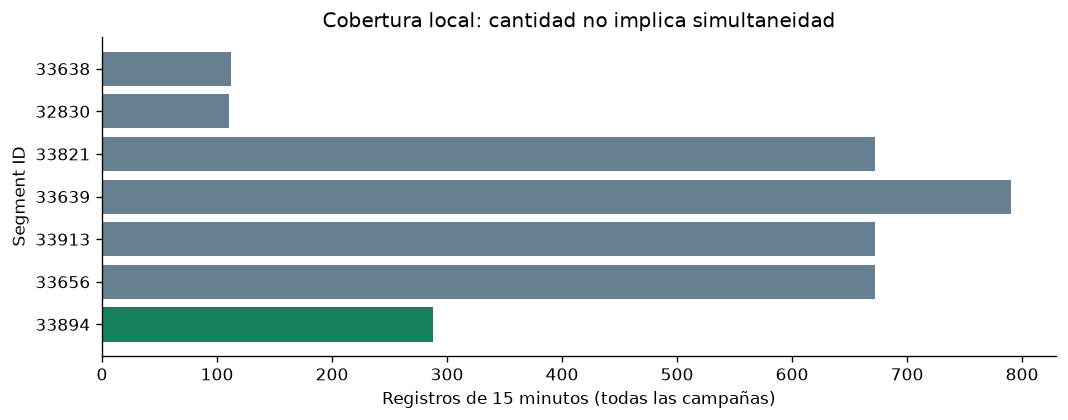

In [9]:
cerca=pd.DataFrame(leer('cercanos'))
cerca['segmentid']=cerca.segmentid.astype(int)
dist=cerca.groupby('segmentid').distancia_m.min()
alternativas=cobertura.merge(dist.rename('distancia_m'),on='segmentid').sort_values('distancia_m')
display(alternativas.head(12))
alternativas.to_csv(SALIDA/'alternativas_cercanas.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3.6))
seleccion=alternativas[alternativas.segmentid.isin([33894,33821,33656,33913,33639,32830,33638])].copy()
ax.barh(seleccion.segmentid.astype(str),seleccion.registros,color=['#16805d' if sid==33894 else '#667f91' for sid in seleccion.segmentid])
ax.set(xlabel='Registros de 15 minutos (todas las campañas)',ylabel='Segment ID',title='Cobertura local: cantidad no implica simultaneidad')
fig.tight_layout();fig.savefig(SALIDA/'cobertura_cercana.png');plt.show()

## 10. Viabilidad para una futura simulación de eventos discretos

| Categoría | Alcance defendible |
|---|---|
| Observado directamente | Conteo por 15 min, fecha/hora de reloj, sentido, solicitud, ID y ubicación del contador. En 33894: 10–112 vehículos/15 min; 19 043 vehículos en total. |
| Estimable | Perfil de flujo horario de 33894 sumando cuatro intervalos completos: 72 horas, 62–425 veh/h; media global 264,49 veh/h. Hay solo tres días por hora, todos laborables. Se puede describir variación entre esos días, sin atribuir representatividad anual ni actual. |
| Por asumir o conseguir | Llegadas dentro de cada intervalo, dependencia/platoones, giros, ciclos/verdes/desfases, flujo de saturación, almacenamiento, tiempos de recorrido y escenario de bloqueo. Un proceso Poisson/exponencial sería una hipótesis por validar, no un hallazgo de estos conteos. |
| No inferible de este dataset | Trayectorias individuales, espera real, cola y su propagación observada, tiempos de viaje, capacidad bajo bloqueo, demanda no satisfecha y efecto causal de coordinar semáforos. |

**Conclusión explícita:** necesitamos otra fuente para mantener **Seventh Avenue/W29 y W30** como corredor calibrado con datos. Este dataset sirve para un perfil histórico parcial del acceso WB de W29, pero no para calibrar las entradas de ambas intersecciones. Antes de mover el corredor, buscar aforos de giros y accesos en NYC DOT, el [archivo histórico complementario](https://data.cityofnewyork.us/Transportation/Traffic-Volume-Counts-Historical-/btm5-ppia), o medición de campo. Esas fuentes adicionales aún no se han auditado. Para contrastar propagación harán falta también observaciones de colas/señales y bloqueo. Se mantiene la ubicación provisional y no se generan datos sintéticos.